In [1]:
# Import the libraries and load the scaled data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid")

X_scaled = pd.read_csv("Customer_Features_Scaled.csv")

print("Dataset shape:", X_scaled.shape)
print("Missing values:", X_scaled.isnull().sum().sum())

display(X_scaled.head())

Dataset shape: (5044, 7)
Missing values: 0


,Total_Sales,Total_Profit,Total_Units,Order_Count,Product_Count,Average_Sales_Per_Order,Average_Units_Per_Order
0,-0.615087,-0.647189,-0.704700,-0.695062,-0.736485,-0.435020,-0.572066
1,-0.368824,-0.348946,-0.402472,-0.695062,-0.736485,0.192014,0.257588
2,-0.250253,-0.244127,-0.251358,1.305448,1.455803,-0.822079,-0.986893
3,0.317064,0.321666,0.504213,0.305193,0.359659,0.229171,0.465001
4,-0.357879,-0.354737,-0.402472,0.305193,0.359659,-0.630098,-0.779479


In [2]:
# Test cluster counts from 2 to 10
results = []

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    inertia = model.inertia_
    silhouette = silhouette_score(X_scaled, labels)

    results.append({
        "Number_of_Clusters": k,
        "Inertia": inertia,
        "Silhouette_Score": silhouette,
        "Smallest_Cluster_Size": pd.Series(labels).value_counts().min()
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Number_of_Clusters,Inertia,Silhouette_Score,Smallest_Cluster_Size
0,2,20355.1030,0.5188,1128
1,3,15619.5646,0.4039,485
2,4,11846.4973,0.4589,339
3,5,10002.1583,0.4558,133
4,6,8486.7389,0.4749,119
5,7,7502.6812,0.4789,12
6,8,6644.8791,0.4986,8
7,9,5836.1809,0.5005,12
8,10,5276.1643,0.4941,14


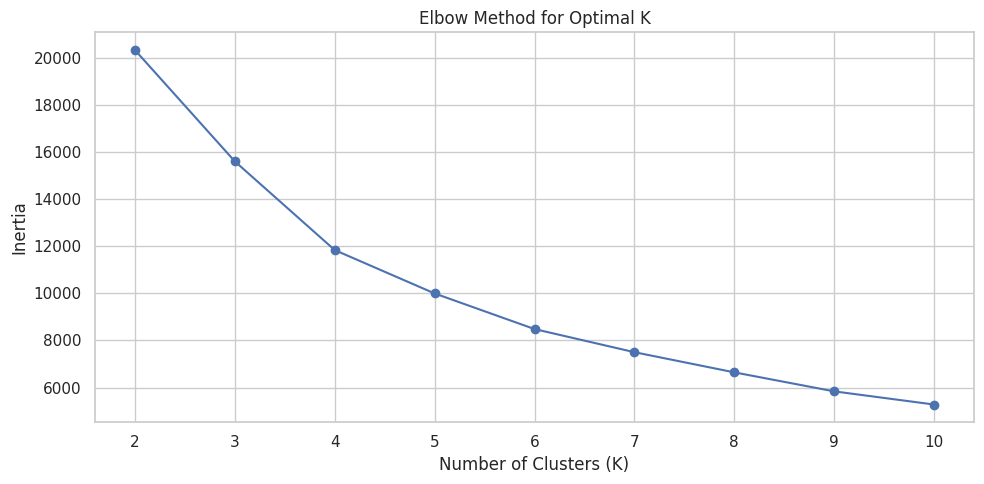

In [3]:
# Plot the Elbow Method
plt.figure(figsize=(10, 5))

plt.plot(
    results_df["Number_of_Clusters"],
    results_df["Inertia"],
    marker="o"
)

plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(range(2, 11))
plt.tight_layout()
plt.show()

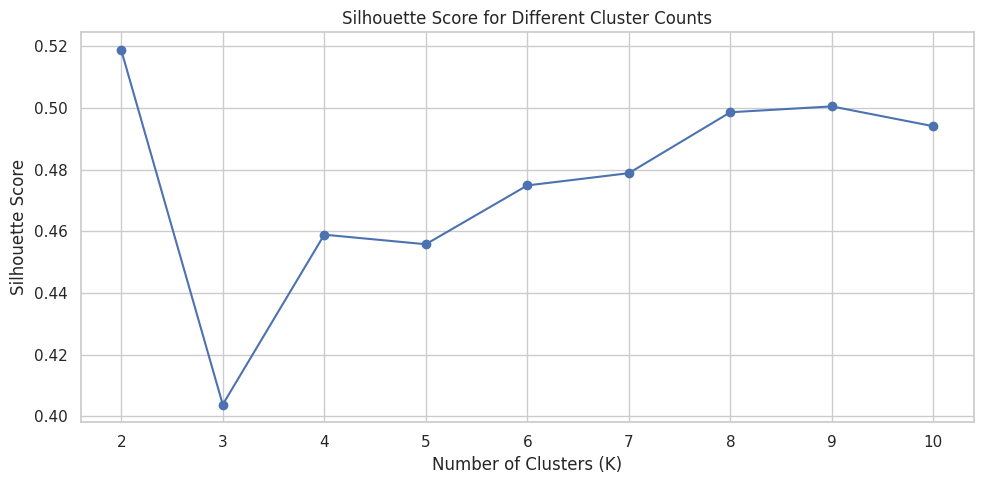

In [4]:
# Plot the Silhouette Scores
plt.figure(figsize=(10, 5))

plt.plot(
    results_df["Number_of_Clusters"],
    results_df["Silhouette_Score"],
    marker="o"
)

plt.title("Silhouette Score for Different Cluster Counts")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 11))
plt.tight_layout()
plt.show()

In [5]:
# Save the model selection results
results_df.to_csv(
    "Clustering_Model_Selection.csv",
    index=False
)

print("Clustering comparison completed.")
print("Results saved to Clustering_Model_Selection.csv")

best_row = results_df.loc[
    results_df["Silhouette_Score"].idxmax()
]

print("Best silhouette K:",
      int(best_row["Number_of_Clusters"]))

print("Best silhouette score:",
      round(best_row["Silhouette_Score"], 4))

Clustering comparison completed.
Results saved to Clustering_Model_Selection.csv
Best silhouette K: 2
Best silhouette score: 0.5188
